# Figure 8 -- injected vs. recovered period (`injected_vs_recovered_period_lw26`)

Injected against recovered orbital period for the `epochalypse` one-companion high-SNR population
and the Lammers & Winn (2026) DR4 forecast, split by whether the period is localized (LW26:
$P_{84}/P_{16} < 1.2$; `epochalypse`: competitive region $< 0.05$ dex). Only
`epochalypse` companions with a significant *periodogram peak* are shown (an acceleration-only
detection has no recovered period: its `best_period` is the argmax of a sub-threshold periodogram).
The upper panels are each class's distribution in
injected period, the side panels its distribution in recovered period -- all of it, and the errant
part ($P_{\rm rec} < P_{\rm inj}/2$ or $P_{\rm rec} > 2\,P_{\rm inj}$) on its own -- normalized to the class total. Solid black lines
mark the Holl et al. (2023) scanning-law spurious periods, $365.25\,{\rm d}/P = 5.8\,m + n$.

Inputs: `catalog/periodograms/characterization_1_companion_high_snr.parquet` and LW26's released
`DR4_master_orbital_fits.csv` (`analysis/data/LW25_GaiaForecasts/`).

In [1]:
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import Image, display

import paperfig as pf          # paths, style, loaders and the shared figure machinery

pf.setup_style()               # Computer Modern, usetex -- the paper's typography
print("catalog :", pf.CATALOG)
print("paper figures         :", pf.PAPER_FIG_DIR)
print("supplementary figures :", pf.SUPP_FIG_DIR)

catalog : /Users/daniel/Desktop/epochalypse_catalog/catalog
paper figures         : /Users/daniel/Desktop/epochalypse_catalog/analysis/paper_figures
supplementary figures : /Users/daniel/Desktop/epochalypse_catalog/analysis/supplementary_figures


## 1. The two surveys

**LW26.** Their released fits, every row at $\Delta\chi^2 > 50$, split at their own 20\% criteria.
The period-only split ($P_{84}/P_{16} < 1.2$) is the like-for-like analogue of a periodogram's
localization; the full characterized split adds the mass criterion.

**`epochalypse`.** The one-companion high-SNR table, restricted to systems whose periodogram peak
clears the null-calibrated threshold, classified *narrow* (period localized: competitive region
$< 0.05$ dex) or *broad*.

In [2]:
from matplotlib.gridspec import GridSpec
from matplotlib.lines import Line2D

EP_POP = "1_companion_high_snr"
LW26_TRIAGE_YR = 7.0                  # LW26 fitted nothing beyond this true period
BASE = pf.BASELINE
YR = pf.YR

C_LW_MEAS, C_LW_NOT = "#A93434", "#DE7D7D"
C_EP_LOC, C_EP_NOT = pf.CLASS_COLORS["narrow"], pf.CLASS_COLORS["broad"]
C_TRIAGE = "#08306B"

LW = pf.EXTERNAL / "LW25_GaiaForecasts"
master = pd.read_csv(LW / "DR4_master_orbital_fits.csv")
P16, P84 = "MCMC period 16th [days]", "MCMC period 84th [days]"
M16, M84 = "MCMC planet mass 16th [M_J]", "MCMC planet mass 84th [M_J]"
lw_char = ((master[P84] / master[P16] < 1.2) & (master[M84] / master[M16] < 1.2)
           & (master["Best-fit planet mass [M_J]"] < 13.0)).to_numpy()
lw_det = ~lw_char
lw_pmeas = (master[P84] / master[P16] < 1.2).to_numpy()          # period to 20%, whatever the mass
lw_Pt = master["True period [days]"].to_numpy(float) / YR
lw_Pb = master["Best-fit period [days]"].to_numpy(float) / YR
print(f"LW26: {len(master):,} fitted (all Delta-chi2 > 50) = {lw_char.sum():,} forecasted characterized "
      f"+ {lw_det.sum():,} forecasted detected")
assert lw_char.sum() == 1938 and lw_det.sum() == 27191
print(f"      period-only split: {lw_pmeas.sum():,} period to 20% + {(~lw_pmeas).sum():,} not")

ep = pf.load_chars(EP_POP, columns=["gaia_source_id", "klass", "top_power", "best_period",
                                   "accel_delta_chi2", "n_epochs"])
n_accel_only = int((ep["detected_cal"].to_numpy() & ~ep["peak_significant_cal"].to_numpy()).sum())
ep = ep[ep["peak_significant_cal"].to_numpy()].reset_index(drop=True)
ep_cls = pf.classes(ep, 1, det_col="peak_significant_cal")        # narrow / broad
ep_char, ep_det = ep_cls == "narrow", ep_cls == "broad"
ep_Pt = ep["period_1"].to_numpy(float)
ep_Pb = ep["best_period"].to_numpy(float)
print(f"epochalypse ({pf.CHAR_LABELS[EP_POP]}): {len(ep):,} with a significant peak = "
      f"{ep_char.sum():,} period localized + {ep_det.sum():,} not localized   "
      f"({n_accel_only:,} acceleration-only detections left out)")

LW26: 29,129 fitted (all Delta-chi2 > 50) = 1,938 forecasted characterized + 27,191 forecasted detected
      period-only split: 10,351 period to 20% + 18,778 not


  1_companion_high_snr     436,883 systems   characterization_1_companion_high_snr.parquet   (SNR_tot >= 5 view)


epochalypse (one companion: high-SNR): 204,054 with a significant peak = 106,332 period localized + 97,722 not localized   (42,105 acceleration-only detections left out)


## 2. The figure

`draw` builds the whole figure. With `errant` a second recovered-period histogram beside each
panel keeps only the systems whose recovered period is at least that factor off the injected one (below
it, or with ``errant_mode="both"`` -- the default -- on either side),
normalized to the same class total, so it is the errant part of the first histogram.

In [3]:
XLIM = (0.03, 300.0)          # injected period [yr]
YLIM = (0.01, 4000.0)         # recovered period [yr]; the periodogram grid ends at 3,700 yr
PB = np.logspace(np.log10(XLIM[0]), np.log10(XLIM[1]), 61)
PF = np.logspace(np.log10(XLIM[0]), np.log10(XLIM[1]), 31)
LW_NAME = "Lammers and Winn, 2026"
BASE_LINE = dict(color="k", ls="--", lw=2.5, alpha=0.3)
EP_NAME = r"\texttt{epochalypse}"

# ---- Holl et al. 2023, Eq. 3: spurious periods from the scanning law, 365.25 / P = 5.8 m + n ----
TOL = 1.2
ERRANT = 2.0                  # the errant side histogram keeps P_rec < P_inj / ERRANT
HOLL = sorted({(m, n, YR / (5.8 * m + n)) for m in range(0, 3) for n in range(-3, 6)
               if 5.8 * m + n > 0 and 10 <= YR / (5.8 * m + n) <= 400}, key=lambda x: x[2])
HALF, JITTER, NDRAW, ZMIN = 0.03, 0.15, 60, 3.0
# drawn: the lines with a significant excess of errant periods in either survey (46.8, 53.7, 91.3 d);
# (1, -2) 96.1 d is a *deficit* in LW26 and 5% above the 91.3 d peak, within one side-panel bin of it
HOLL_DRAWN = [h for h in HOLL if h[:2] in {(1, 2), (1, 1), (0, 4)}]


def wrong(Pt, Pb):
    return np.abs(np.log(Pb / Pt)) > np.log(TOL)


def line_excess(Pb_days, seed=20261009):
    """Per Holl line: (m, n, P, observed within +-HALF, expected after +-JITTER dex smearing, z)."""
    rng = np.random.default_rng(seed)
    lp = np.log10(Pb_days)
    smeared = [lp + rng.uniform(-JITTER, JITTER, len(lp)) for _ in range(NDRAW)]
    out = []
    for m, n, P in HOLL:
        obs = int(np.sum(np.abs(np.log(Pb_days / P)) < np.log(1 + HALF)))
        exp = float(np.mean([np.sum(np.abs(x - np.log10(P)) < np.log10(1 + HALF)) for x in smeared]))
        out.append((m, n, P, obs, exp, (obs - exp) / np.sqrt(max(exp, 1.0))))
    return out


def holl_hot(lw_sel, ep_sel):
    """The Holl lines with a >= ZMIN excess of wrong periods (10-400 d) in either survey's class."""
    rows = {}
    for name, Pt, Pb in ((LW_NAME, lw_Pt[lw_sel], lw_Pb[lw_sel]), ("epochalypse", ep_Pt[ep_sel], ep_Pb[ep_sel])):
        Pd = Pb[wrong(Pt, Pb)] * YR
        Pd = Pd[(Pd >= 10) & (Pd <= 400)]
        if len(Pd) >= 20:
            rows[name] = line_excess(Pd)
    hot = sorted({(r[0], r[1], r[2]) for rr in rows.values() for r in rr if r[5] >= ZMIN},
                 key=lambda x: x[2])
    return hot, rows


MAR_XLIM = (2e-4, 1.0)        # the side histograms' fraction axis (log)


def step_outline(ax, f, edges, floor, **kw):
    """A horizontal step outline that drops to ``floor`` at both ends of every populated run of bins,
    so a histogram that ends at a non-zero bin still steps down instead of stopping mid-air."""
    f = np.asarray(f, float)
    i, n = 0, len(f)
    while i < n:
        if not f[i] > 0:
            i += 1
            continue
        j = i
        while j < n and f[j] > 0:
            j += 1
        xs, ys = [floor], [edges[i]]
        for k in range(i, j):
            xs += [f[k], f[k]]
            ys += [edges[k], edges[k + 1]]
        xs.append(floor)
        ys.append(edges[j])
        ax.plot(xs, ys, solid_joinstyle="miter", **kw)
        i = j


def frac_not_measured(Pt, measured, bins, nmin=20):
    """Fraction of detections that are NOT measured per true-period bin, with a binomial 1-sigma."""
    n, _ = np.histogram(Pt, bins)
    k, _ = np.histogram(Pt[~measured], bins)
    f = np.where(n >= nmin, k / np.maximum(n, 1), np.nan)
    e = np.sqrt(f * (1 - f) / np.maximum(n, 1))
    return f, e


def draw(stem, lw_meas, titles=("recovered orbital period localized", "recovered orbital period not localized"),
         errant=None, errant_mode="both", paper=False):
    """The figure, with LW26 split into localized / not localized by ``lw_meas``.

    ``errant_mode="below"`` keeps P_rec < P_inj / errant in the errant histogram; ``"both"`` also keeps
    P_rec > errant * P_inj, so the grid-edge rail enters it too."""
    FS_TICK, FS_LAB, FS_TITLE, FS_LEG, FS_TXT = 20, 24, 27, 17.5, 19
    n_m = 2 if errant else 1
    widths = [3.0] + [0.9] * n_m + [0.22, 3.0] + [0.9] * n_m
    cols = (0, n_m + 2)
    fig = plt.figure(figsize=(20 + 2.4 * (n_m - 1), 9.6))
    gs = GridSpec(2, len(widths), figure=fig, height_ratios=[1.0, 3.0], width_ratios=widths,
                  hspace=0.06, wspace=0.05, left=0.07, right=0.985, top=0.92, bottom=0.11)
    ax_main = [fig.add_subplot(gs[1, c]) for c in cols]
    ax_main[1].sharey(ax_main[0])
    ax_top = [fig.add_subplot(gs[0, c], sharex=a) for c, a in zip(cols, ax_main)]
    ax_top[1].sharey(ax_top[0])
    ax_mar = [[fig.add_subplot(gs[1, c + 1 + k], sharey=ax_main[0]) for k in range(n_m)] for c in cols]
    for a in [a for row in ax_mar for a in row][1:]:
        a.sharex(ax_mar[0][0])
    YB = np.logspace(np.log10(YLIM[0]), np.log10(YLIM[1]), 85)

    panels = [(ep_char, lw_meas, C_LW_MEAS, C_EP_LOC, titles[0]),
              (ep_det, ~lw_meas, C_LW_NOT, C_EP_NOT, titles[1])]
    table = {}
    for j, (em, lm, col, ecol, title) in enumerate(panels):
        # --- top: each class's distribution in injected period, as a fraction of that class ---
        ax = ax_top[j]
        for P, c, lw_, fill in ((ep_Pt[em], ecol, 1.8, True), (lw_Pt[lm], col, 2.4, False)):
            w = np.full(len(P), 1 / len(P))
            if fill:
                ax.hist(P, PB, color=c, alpha=0.25, histtype="stepfilled", lw=0, weights=w)
            ax.hist(P, PB, color=c, histtype="step", lw=lw_, weights=w)
        ax.set_title(title, fontsize=FS_TITLE, pad=10)
        ax.tick_params(labelbottom=False)

        # --- right: each class's distribution in recovered period (and the errant part) ---
        for k, axm in enumerate(ax_mar[j]):
            for Pt, Pb, c, lw_, fill in ((ep_Pt[em], ep_Pb[em], ecol, 1.8, True),
                                         (lw_Pt[lm], lw_Pb[lm], col, 2.4, False)):
                off = (Pb < Pt / errant) | ((Pb > Pt * errant) if errant_mode == "both" else False)
                P = Pb if k == 0 else Pb[off]
                f = np.histogram(P, YB)[0] / len(Pb)
                if fill:
                    axm.stairs(f, YB, orientation="horizontal", fill=True, color=c, alpha=0.25, lw=0)
                step_outline(axm, f, YB, MAR_XLIM[0], color=c, lw=lw_, zorder=3)
            axm.set_xscale("log"); axm.set_xlim(*MAR_XLIM)
            axm.set_xticks([1e-3, 1e-1])
            axm.tick_params(labelleft=False)
            axm.set_xlabel("fraction of\npopulation", fontsize=FS_LAB)
            axm.axhline(BASE, **BASE_LINE)
            axm.grid(alpha=0.12, which="major")
            if errant:
                lab = (rf"$P_{{\rm rec}} < P_{{\rm inj}}/{errant:g}$" if errant_mode == "below" else
                       rf"$P_{{\rm rec}} < P_{{\rm inj}}/{errant:g}$" + "\n" + rf"or $P_{{\rm rec}} > {errant:g}\,P_{{\rm inj}}$")
                axm.set_title("all" if k == 0 else lab, fontsize=FS_LAB - 3, pad=8)

        # --- main: injected vs recovered period ---
        ax = ax_main[j]
        ax.scatter(ep_Pt[em], ep_Pb[em], s=1.5, color=ecol, alpha=0.35, linewidths=0, marker="s",
                   rasterized=True, zorder=2)
        ax.scatter(lw_Pt[lm], lw_Pb[lm], s=4, color=col, alpha=0.6, linewidths=0, marker="o",
                   rasterized=True, zorder=3)
        ax.plot(XLIM, XLIM, color="k", ls="--", lw=1.0, zorder=4)
        ax.set_xscale("log"); ax.set_yscale("log")
        ax.set_xlim(*XLIM); ax.set_ylim(*YLIM)
        ax.set_xlabel("injected period [yr]", fontsize=FS_LAB)
        ax.grid(alpha=0.12, which="major")

        # Holl et al. (2023) lines, labelled "(m, n) P d" at the right edge
        _, table[title] = holl_hot(lm, em)
        hot = HOLL_DRAWN
        fig.canvas.draw()
        rend = fig.canvas.get_renderer()
        to_data = ax.transData.inverted()
        tops = {}
        for m, n, P in hot:
            for a in (ax, *ax_mar[j]):
                a.axhline(P / YR, color="0.2", lw=1.0, zorder=1)
            x_right, placed = XLIM[1] / 1.12, False
            for col_i in range(4):
                for va in ("top", "bottom"):
                    t = ax.text(x_right, P / YR, f"$({m},{n})$ {P:.1f} d", ha="right", va=va,
                                fontsize=FS_LEG - 2, color="0.15", zorder=6,
                                bbox=dict(boxstyle="square,pad=0.08", fc="white", ec="none", alpha=0.7))
                    (x0, y0), (_, y1) = to_data.transform(t.get_window_extent(rend).get_points())
                    if np.log10(y0) > tops.get(col_i, -np.inf):
                        tops[col_i], placed = np.log10(y1), True
                        break
                    t.remove()
                if placed:
                    break
                x_right = x0 / 1.3

        leg_kw = dict(fontsize=FS_LEG, frameon=True, framealpha=0.95, edgecolor="none",
                      borderaxespad=0.3, handlelength=1.2, handletextpad=0.5)
        pops = ax.legend(handles=[Line2D([], [], marker="s", ls="", color=ecol, ms=8, label=EP_NAME),
                                  Line2D([], [], marker="o", ls="", color=col, ms=8, label=LW_NAME)],
                         loc="upper left", **{**leg_kw, "handlelength": 0.8, "handletextpad": 0.4})
        if hot:
            ax.add_artist(pops)
            ax.legend(handles=[Line2D([], [], color="0.2", lw=1.2,
                                      label="Holl et al. (2023)\nscanning law spurious\nperiod $(m, n)$:\n"
                                            r"$365.25\,{\rm d}/P = 5.8\,m + n$")],
                      loc="lower right",
                      **{**leg_kw, "fontsize": FS_LEG - 4, "handlelength": 1.0, "borderaxespad": 0.1})

    ax_main[0].set_ylabel("recovered period [yr]", fontsize=FS_LAB)
    ax_main[1].tick_params(labelleft=False)
    ax_top[1].tick_params(labelleft=False)
    ax_top[0].set_ylabel("fraction of\npopulation", fontsize=FS_LAB)
    ax_top[0].set_ylim(0, ax_top[0].get_ylim()[1] * 1.3)
    for ax in [*ax_top, *ax_main, *ax_mar[0], *ax_mar[1]]:
        ax.tick_params(labelsize=FS_TICK)

    for ax in [*ax_top, *ax_main]:
        ax.axvline(BASE, zorder=5, **BASE_LINE)
        ax.axvline(LW26_TRIAGE_YR, color=C_TRIAGE, ls="-", lw=2.6, zorder=5)
    for ax in ax_main:
        ax.axhline(BASE, zorder=5, **BASE_LINE)
    base_lab = dict(fontsize=FS_LEG - 4, color="k", alpha=0.75, zorder=6,
                    bbox=dict(boxstyle="round,pad=0.1", fc="white", ec="none", alpha=0.8))
    for ax in ax_main:
        ax.text(BASE / 1.23, 280.0, r"\textit{Gaia} DR4 baseline", rotation=90, ha="center", va="center",
                **base_lab)
        ax.text(XLIM[0] * 1.25, BASE * 1.2, r"\textit{Gaia} DR4 baseline", ha="left", va="bottom",
                **base_lab)
        ax.text(LW26_TRIAGE_YR * 1.12, 1800.0, "Lammers and Winn, 2026\nmaximum period = 7~yr",
                fontsize=FS_TXT - (4 if errant else 2), color=C_TRIAGE, ha="left", va="top", zorder=6)

    pf.save(fig, stem, dpi=150, paper=paper)
    return fig, table


def print_holl(table):
    """The per-line excess behind the drawn lines: wrong periods within +-HALF of each line."""
    for title, rows in table.items():
        print(f"{title.splitlines()[0]}: wrong periods (off by > x{TOL:g}, 10-400 d) within +-{100 * HALF:.0f}% "
              f"of each Holl line, observed / expected, z   (* = drawn)")
        names = list(rows)
        print(f"  {'(m, n)':>8s} {'P [d]':>6s}   " + "   ".join(f"{nm:>26s}" for nm in names))
        for i, (m, n, P) in enumerate(HOLL):
            cells = [f"{rows[nm][i][3]:4d} / {rows[nm][i][4]:6.1f}  z={rows[nm][i][5]:+5.1f}" for nm in names]
            flag = "  *" if (m, n, P) in HOLL_DRAWN else ""
            print(f"  {str((m, n)):>8s} {P:6.1f}   " + "   ".join(f"{c:>26s}" for c in cells) + flag)

### The characterization split

LW26 split at their *characterization* criteria (period **and** mass to 20\%, best-fit mass
$< 13\,M_{\rm J}$) against everything else they fitted -- a supplementary variant: the mass criterion
has no periodogram analogue.

  wrote analysis/supplementary_figures/injected_vs_recovered_period_lw26_characterized_errant.pdf, analysis/supplementary_figures/injected_vs_recovered_period_lw26_characterized_errant.png


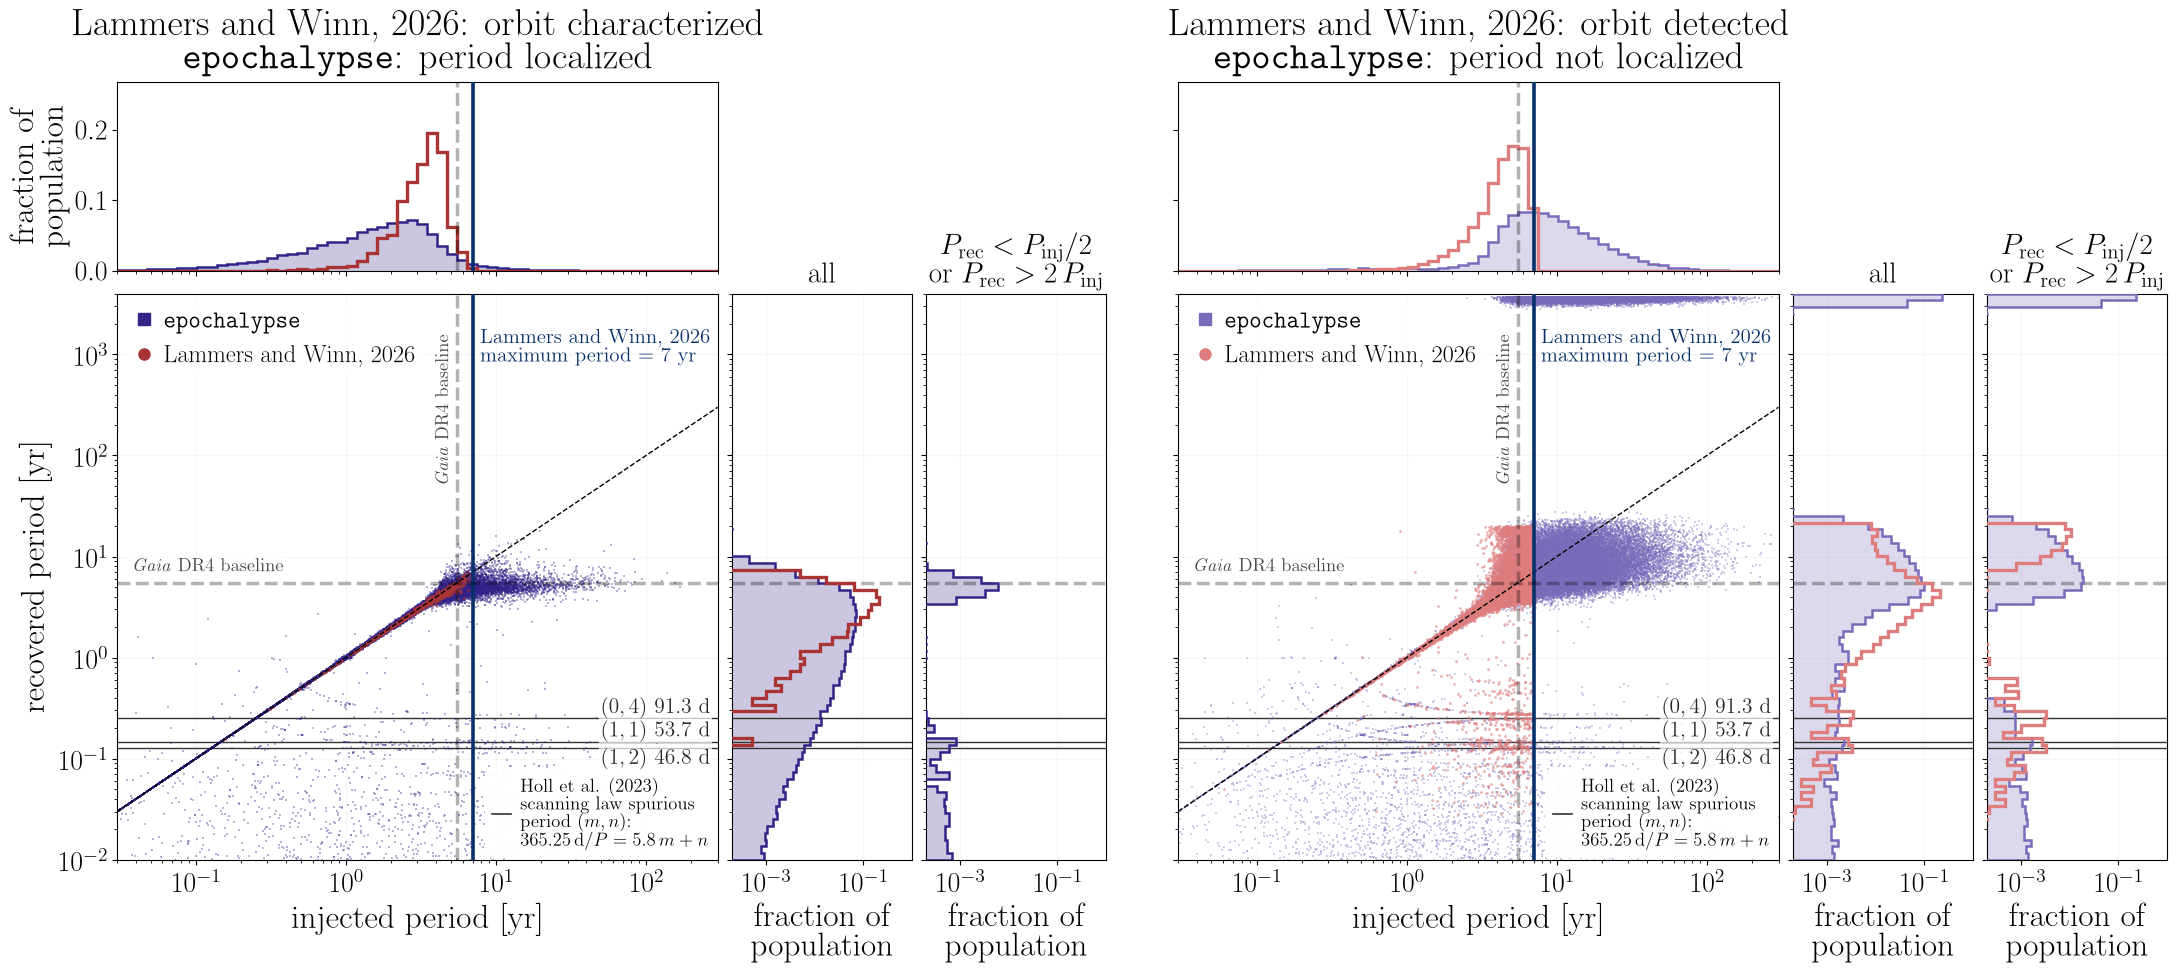

Lammers and Winn, 2026: orbit characterized: wrong periods (off by > x1.2, 10-400 d) within +-3% of each Holl line, observed / expected, z   (* = drawn)
    (m, n)  P [d]                  epochalypse
    (2, 5)   22.0          8 /   18.1  z= -2.4
    (2, 4)   23.4         17 /   16.4  z= +0.2
    (2, 3)   25.0         32 /   13.7  z= +5.0
    (2, 2)   26.9         23 /   14.5  z= +2.2
    (2, 1)   29.0          9 /   14.4  z= -1.4
    (2, 0)   31.5         24 /   16.7  z= +1.8
    (1, 5)   33.8          6 /   18.6  z= -2.9
   (2, -1)   34.5          6 /   18.4  z= -2.9
    (1, 4)   37.3         10 /   18.7  z= -2.0
   (2, -2)   38.0          8 /   19.0  z= -2.5
    (1, 3)   41.5         30 /   20.8  z= +2.0
   (2, -3)   42.5         30 /   20.5  z= +2.1
    (1, 2)   46.8         34 /   20.1  z= +3.1  *
    (1, 1)   53.7         47 /   21.1  z= +5.7  *
    (1, 0)   63.0         13 /   20.4  z= -1.6
    (0, 5)   73.0         18 /   14.5  z= +0.9
   (1, -1)   76.1         21 /   11.9  z= 

In [4]:
fig, char_errant_holl = draw("injected_vs_recovered_period_lw26_characterized_errant", lw_char,
                             titles=(f"{LW_NAME}: orbit characterized\n{EP_NAME}: period localized",
                                     f"{LW_NAME}: orbit detected\n{EP_NAME}: period not localized"),
                             errant=ERRANT)
plt.show()
print_holl(char_errant_holl)

### Numbers for the text

Keyed to the numbered items in the paper's discussion of this figure. LW26's *localized* is the
period-only split; *characterized* is their full criterion. *Agrees* = best period within
$\times 1.2$ of the injected one.

In [5]:
T_MAX = BASE / np.sqrt(2)                          # the max recoverable period
RAIL_YR = 1000.0                                   # the grid-edge rail
pc = lambda k, n: f"{k:,} / {n:,} = {k / n:5.1%}" if n else "--"
SURVEYS = ((LW_NAME, lw_Pt, lw_Pb, lw_pmeas), ("epochalypse", ep_Pt, ep_Pb, ep_char))

print(f"(2) injected P < T_DR4 ({BASE:g} yr): recovered period agrees with injected to x{TOL:g}")
for name, Pt, Pb, loc in SURVEYS:
    s, ok = Pt < BASE, ~wrong(Pt, Pb)
    print(f"  {name:22s} all {pc((s & ok).sum(), s.sum())}   localized {pc((s & loc & ok).sum(), (s & loc).sum())}"
          f"   not localized {pc((s & ~loc & ok).sum(), (s & ~loc).sum())}")

print(f"\n(2) localized systems: share with injected P < T_DR4, and localized share on each side of T_DR4")
for name, Pt, Pb, loc in SURVEYS:
    s = Pt < BASE
    print(f"  {name:22s} localized with P < T_DR4: {pc((loc & s).sum(), loc.sum())}   "
          f"localized | P < T_DR4: {pc((loc & s).sum(), s.sum())}   localized | P > T_DR4: {pc((loc & ~s).sum(), (~s).sum())}")
s = lw_Pt < BASE
print(f"  {'(LW26 characterized)':22s} characterized with P < T_DR4: {pc((lw_char & s).sum(), lw_char.sum())}   "
      f"characterized | P < T_DR4: {pc((lw_char & s).sum(), s.sum())}   characterized | P > T_DR4: "
      f"{pc((lw_char & ~s).sum(), (~s).sum())}")

print(f"\n(3) injected P > T_DR4: recovered period off by more than x{TOL:g}; not-localized systems beyond T_DR4")
for name, Pt, Pb, loc in SURVEYS:
    s, bad = Pt > BASE, wrong(Pt, Pb)
    print(f"  {name:22s} wrong: all {pc((s & bad).sum(), s.sum())}   localized {pc((s & loc & bad).sum(), (s & loc).sum())}"
          f"   not localized {pc((s & ~loc & bad).sum(), (s & ~loc).sum())}")
    print(f"  {'':22s} not localized with P > T_DR4: {pc((~loc & s).sum(), (~loc).sum())}")
m = (ep_Pt > BASE) & (ep_Pb < RAIL_YR)
print(f"  {'epochalypse, no rail':22s} wrong: all {pc((m & wrong(ep_Pt, ep_Pb)).sum(), m.sum())}"
      f"   of which recovered P < injected: {pc((m & (ep_Pb < ep_Pt / TOL)).sum(), (m & wrong(ep_Pt, ep_Pb)).sum())}")

print(f"\n(4) epochalypse grid-edge rail: recovered P > {RAIL_YR:g} yr (grid max {np.nanmax(ep_Pb):,.0f} yr)")
rail = ep_Pb > RAIL_YR
print(f"  rail, not localized: {pc((rail & ep_det).sum(), ep_det.sum())} of the not-localized class;  "
      f"localized on the rail: {(rail & ep_char).sum():,};  of all significant peaks: {pc(rail.sum(), len(ep_Pb))}")
print(f"  recovered P on the rail: 1st-50th-99th percentile {np.percentile(ep_Pb[rail], [1, 50, 99]).round(0)} yr")
for lab, cut in ((f"T_baseline/sqrt(2) = {T_MAX:.2f} yr", T_MAX), (f"T_DR4 = {BASE:g} yr", BASE),
                 (f"{LW26_TRIAGE_YR:g} yr", LW26_TRIAGE_YR)):
    print(f"  rail with injected P > {lab:28s}: {pc((rail & (ep_Pt > cut)).sum(), rail.sum())}")
print(f"  injected P on the rail: 1st-50th-99th percentile {np.percentile(ep_Pt[rail], [1, 50, 99]).round(2)} yr")

(2) injected P < T_DR4 (5.5 yr): recovered period agrees with injected to x1.2
  Lammers and Winn, 2026 all 17,761 / 21,647 = 82.0%   localized 9,510 / 10,098 = 94.2%   not localized 8,251 / 11,549 = 71.4%
  epochalypse            all 117,481 / 126,988 = 92.5%   localized 98,284 / 100,351 = 97.9%   not localized 19,197 / 26,637 = 72.1%

(2) localized systems: share with injected P < T_DR4, and localized share on each side of T_DR4
  Lammers and Winn, 2026 localized with P < T_DR4: 10,098 / 10,351 = 97.6%   localized | P < T_DR4: 10,098 / 21,647 = 46.6%   localized | P > T_DR4: 253 / 7,482 =  3.4%
  epochalypse            localized with P < T_DR4: 100,351 / 106,332 = 94.4%   localized | P < T_DR4: 100,351 / 126,988 = 79.0%   localized | P > T_DR4: 5,981 / 77,066 =  7.8%
  (LW26 characterized)   characterized with P < T_DR4: 1,874 / 1,938 = 96.7%   characterized | P < T_DR4: 1,874 / 21,647 =  8.7%   characterized | P > T_DR4: 64 / 7,482 =  0.9%

(3) injected P > T_DR4: recovered period o

### The fraction of detections without a measured period

  wrote analysis/supplementary_figures/fraction_period_not_measured_lw26.pdf, analysis/supplementary_figures/fraction_period_not_measured_lw26.png


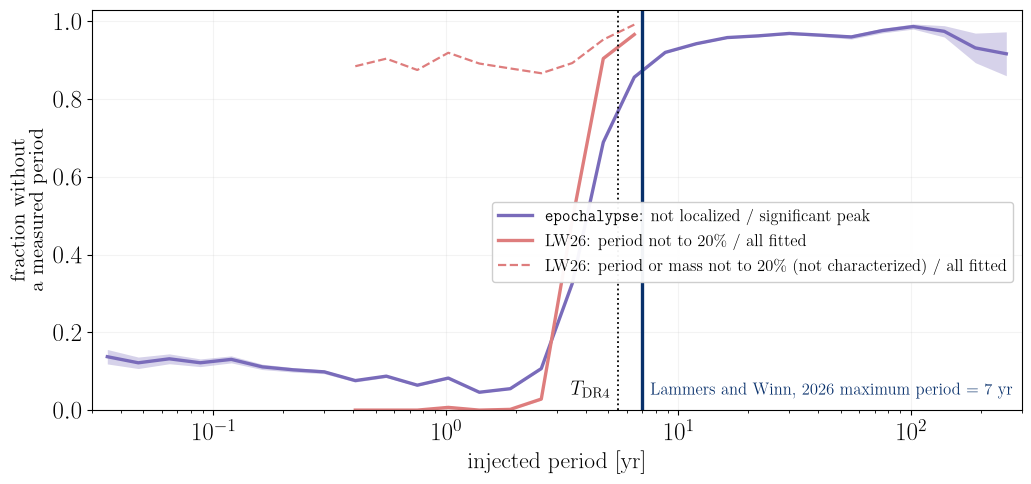

LW26 (period to 20%)  : half of significant signals lack a measured period at P ~ 3.5 yr (0.64 T_DR4)
epochalypse           : half of significant signals lack a measured period at P ~ 4.1 yr (0.74 T_DR4)


In [6]:
fig, ax = plt.subplots(figsize=(12, 5.2))
PC = np.sqrt(PF[1:] * PF[:-1])
f, e = frac_not_measured(ep_Pt, ep_char, PF)
ax.fill_between(PC, f - e, f + e, color=C_EP_NOT, alpha=0.3, lw=0)
ax.plot(PC, f, color=C_EP_NOT, lw=2.4, label=r"\texttt{epochalypse}: not localized / significant peak")
f, e = frac_not_measured(lw_Pt, lw_pmeas, PF)
ax.fill_between(PC, f - e, f + e, color=C_LW_NOT, alpha=0.3, lw=0)
ax.plot(PC, f, color=C_LW_NOT, lw=2.4, label=r"LW26: period not to 20\% / all fitted")
f, e = frac_not_measured(lw_Pt, lw_char, PF)
ax.plot(PC, f, color=C_LW_NOT, lw=1.6, ls="--",
        label=r"LW26: period or mass not to 20\% (not characterized) / all fitted")
ax.axvline(BASE, color="k", ls=":", lw=1.3)
ax.text(BASE * 0.92, 0.04, r"$T_{\rm DR4}$", fontsize=14, ha="right")
ax.axvline(LW26_TRIAGE_YR, color=C_TRIAGE, lw=2.4)
ax.text(LW26_TRIAGE_YR * 1.08, 0.04, "Lammers and Winn, 2026 maximum period = 7~yr", fontsize=12, color=C_TRIAGE)
ax.set_xscale("log"); ax.set_xlim(*XLIM); ax.set_ylim(0, 1.03)
ax.set_xlabel("injected period [yr]", fontsize=17)
ax.set_ylabel("fraction without\na measured period", fontsize=15)
ax.legend(fontsize=12, loc="center right", bbox_to_anchor=(1.0, 0.42), frameon=True, framealpha=0.95)
ax.grid(alpha=0.15)
pf.save(fig, "fraction_period_not_measured_lw26", dpi=150)
plt.show()

for name, Pt, meas in (("LW26 (period to 20%)", lw_Pt, lw_pmeas), ("epochalypse", ep_Pt, ep_char)):
    f, _ = frac_not_measured(Pt, meas, PF)
    good = np.isfinite(f) & (PC > 0.3)
    x, y = np.log10(PC[good]), f[good]
    i = np.argmax(y >= 0.5)
    p50 = 10 ** np.interp(0.5, y[i - 1:i + 1], x[i - 1:i + 1])
    print(f"{name:22s}: half of significant signals lack a measured period at P ~ {p50:.1f} yr "
          f"({p50 / BASE:.2f} T_DR4)")

## 3. The paper figure

Both surveys split on whether the *period* is localized (LW26: $P_{84}/P_{16} < 1.2$;
`epochalypse`: competitive region $< 0.05$ dex) -- the like-for-like comparison. Beside each panel the
recovered-period histogram of the whole class and of its errant part ($P_{\rm rec} < P_{\rm inj}/2$ or $P_{\rm rec} > 2\,P_{\rm inj}$): the scanning-law aliases below,
the periodogram grid-edge rail above.

  wrote analysis/paper_figures/injected_vs_recovered_period_lw26.pdf, analysis/paper_figures/injected_vs_recovered_period_lw26.png


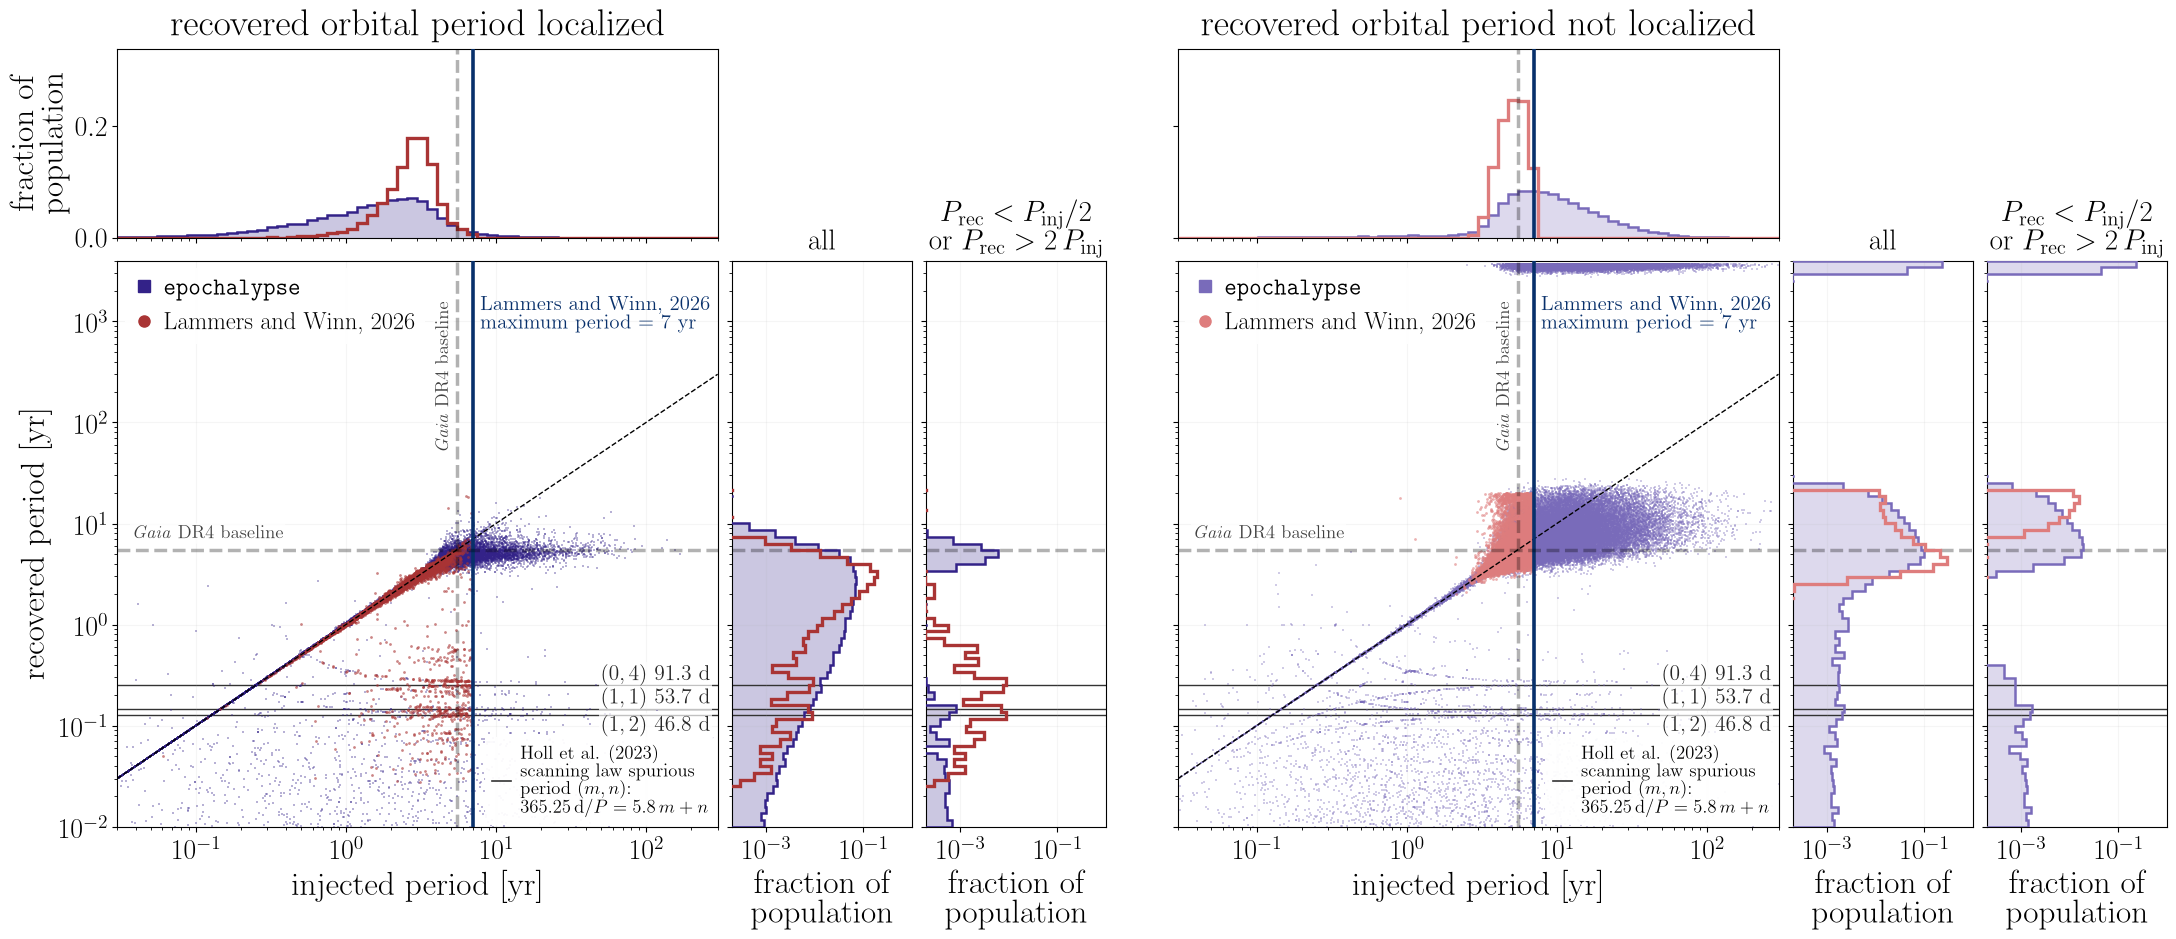

Lammers and Winn 2026: period localized  below P_inj/2:    628 of 10,351 ( 6.1%);  P_rec < 1 yr: 97.6%, within +-3% of any Holl line: 39.8%, of a drawn line: 17.0%
                                         above 2 P_inj:      3 ( 0.0%), on the rail (P_rec > 1000 yr):      0
Lammers and Winn 2026: not localized     below P_inj/2:      3 of 18,778 ( 0.0%);  P_rec < 1 yr:  0.0%, within +-3% of any Holl line:  0.0%, of a drawn line:  0.0%
                                         above 2 P_inj:  1,138 ( 6.1%), on the rail (P_rec > 1000 yr):      0
epochalypse: period localized            below P_inj/2:  3,091 of 106,332 ( 2.9%);  P_rec < 1 yr: 51.6%, within +-3% of any Holl line:  9.3%, of a drawn line:  2.8%
                                         above 2 P_inj:     24 ( 0.0%), on the rail (P_rec > 1000 yr):      0
epochalypse: period not localized        below P_inj/2: 14,235 of 97,722 (14.6%);  P_rec < 1 yr: 24.9%, within +-3% of any Holl line:  5.0%, of a drawn line:  1.3%
             

In [7]:
fig, main_holl = draw("injected_vs_recovered_period_lw26", lw_pmeas, errant=ERRANT, errant_mode="both", paper=True)
plt.show()

# how much of each class is errant on each side, and where the low side sits
# (within +-HALF of any Holl line, and of the drawn ones)
at_any = lambda P: np.any([np.abs(np.log(P / h[2])) < np.log(1 + HALF) for h in HOLL], axis=0)
at_sb = lambda P: np.any([np.abs(np.log(P / h[2])) < np.log(1 + HALF) for h in HOLL_DRAWN], axis=0)
for name, Pt, Pb, cls in (("Lammers and Winn 2026: period localized", lw_Pt, lw_Pb, lw_pmeas),
                          ("Lammers and Winn 2026: not localized", lw_Pt, lw_Pb, ~lw_pmeas),
                          ("epochalypse: period localized", ep_Pt, ep_Pb, ep_char),
                          ("epochalypse: period not localized", ep_Pt, ep_Pb, ep_det)):
    e, hi = cls & (Pb < Pt / ERRANT), cls & (Pb > Pt * ERRANT)
    Pd = Pb[e] * YR
    print(f"{name:40s} below P_inj/{ERRANT:g}: {e.sum():6,d} of {cls.sum():6,d} ({e.mean() / cls.mean():5.1%})"
          + (f";  P_rec < 1 yr: {np.mean(Pd < YR):5.1%}, within +-{100 * HALF:.0f}% of any Holl line: {at_any(Pd).mean():5.1%}, of a drawn line: {at_sb(Pd).mean():5.1%}"
             if e.sum() else "")
          + f"\n{'':40s} above {ERRANT:g} P_inj: {hi.sum():6,d} ({hi.mean() / cls.mean():5.1%}), on the rail (P_rec > 1000 yr): {(hi & (Pb > 1000)).sum():6,d}")
print_holl(main_holl)